# ML Assignment 5 - K-Means clustering with the elbow method

**Problem statement:** implement K-Means clustering on the sales dataset (`sales_data_sample.csv`) and determine the number of clusters with the elbow method (plot the within-cluster sum of squares against k and pick the bend).

**Libraries used:** pandas, numpy (data), scikit-learn (`KMeans`, `StandardScaler`), matplotlib (elbow plot).

**Driver:** the Kaggle *Sample Sales Data* file is not available offline, so a seeded synthetic table with the same numeric columns is generated (three hidden customer segments). To use the real file set `CSV_PATH = "sales_data_sample.csv"`. No input is taken at runtime.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

CSV_PATH = None  # e.g. "sales_data_sample.csv" (read with encoding="latin-1")

## 1. Load the data and select numeric features

In [2]:
def make_data(n=900, seed=3):
    rng = np.random.default_rng(seed)
    segment = rng.integers(0, 3, n)  # three hidden groups: small, medium and bulk orders
    qty = np.array([20, 35, 50])[segment] + rng.normal(0, 3, n)
    price = np.array([45, 75, 110])[segment] + rng.normal(0, 6, n)
    return pd.DataFrame({"ORDERNUMBER": np.arange(10000, 10000 + n), "QUANTITYORDERED": qty.round(),
                         "PRICEEACH": price.round(2), "SALES": (qty * price).round(2),
                         "MSRP": (price * 1.15).round()})


df = pd.read_csv(CSV_PATH, encoding="latin-1") if CSV_PATH else make_data()
features = ["QUANTITYORDERED", "PRICEEACH", "SALES"]
print(df[features].describe().round(2).to_string())

# K-Means uses distances, so every feature is standardised to mean 0 and standard deviation 1
X = StandardScaler().fit_transform(df[features].dropna())

       QUANTITYORDERED  PRICEEACH    SALES
count           900.00     900.00   900.00
mean             34.94      76.43  2979.08
std              12.31      26.54  1878.68
min              11.00      28.53   470.06
25%              22.75      49.23  1053.24
50%              35.00      75.04  2626.23
75%              48.00     104.81  5147.61
max              58.00     128.81  6780.61


## 2. Elbow method: within-cluster sum of squares (inertia) for k = 1..10

k =  1   WCSS =    2700.00
k =  2   WCSS =     658.54
k =  3   WCSS =     122.71
k =  4   WCSS =     104.52
k =  5   WCSS =      88.45
k =  6   WCSS =      75.21
k =  7   WCSS =      66.92
k =  8   WCSS =      61.25
k =  9   WCSS =      54.76
k = 10   WCSS =      49.94

Elbow (bend of the curve) at k = 3


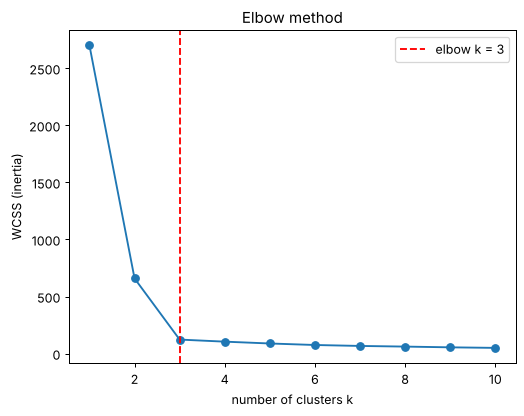

In [3]:
ks = list(range(1, 11))
inertia = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
for k, value in zip(ks, inertia):
    print(f"k = {k:>2}   WCSS = {value:10.2f}")

# the elbow is the point farthest from the straight line joining the first and last points
points = np.column_stack([ks, inertia])
line = (points[-1] - points[0]) / np.linalg.norm(points[-1] - points[0])
vectors = points - points[0]
distances = np.abs(vectors[:, 0] * line[1] - vectors[:, 1] * line[0])
best_k = ks[int(np.argmax(distances))]
print("\nElbow (bend of the curve) at k =", best_k)

plt.plot(ks, inertia, "o-")
plt.axvline(best_k, color="red", linestyle="--", label=f"elbow k = {best_k}")
plt.xlabel("number of clusters k")
plt.ylabel("WCSS (inertia)")
plt.title("Elbow method")
plt.legend()

## 3. Final clustering with the chosen k

         QUANTITYORDERED  PRICEEACH   SALES  orders
cluster                                            
0                   35.0       75.4  2638.4     316
1                   20.3       45.4   925.6     297
2                   50.0      109.6  5479.2     287


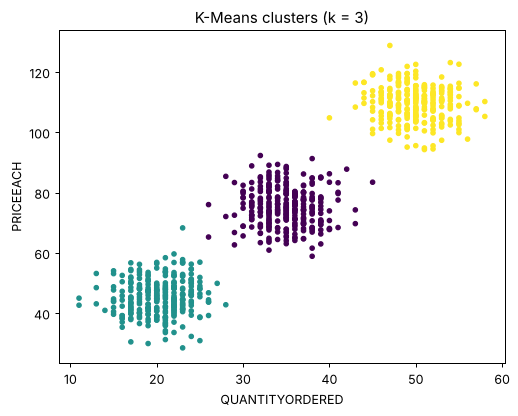

In [4]:
model = KMeans(n_clusters=best_k, n_init=10, random_state=0).fit(X)
result = df.dropna(subset=features).copy()
result["cluster"] = model.labels_
print(result.groupby("cluster")[features].mean().round(1).assign(orders=result.groupby("cluster").size()).to_string())

plt.scatter(result["QUANTITYORDERED"], result["PRICEEACH"], c=result["cluster"], cmap="viridis", s=12)
plt.xlabel("QUANTITYORDERED")
plt.ylabel("PRICEEACH")
plt.title(f"K-Means clusters (k = {best_k})")

**Conclusion:** the elbow plot shows the WCSS dropping sharply until the bend and slowly after it, so adding more clusters than that gives little benefit. Each cluster is a group of orders with similar quantity and price.